# Ecuaciones de *Higher order spectral analysis of ECG signals* (Kotriwar et al., 2018)
Una función por ecuación: (1) desviación del detrending, (2) compresión, (3) bispectro, (4) bicoherencia.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Ec. (1) — Desviación δ(n) entre señal original y detrendizada
$$\delta_{(n)}=\frac{1}{k}\sum_{i=1}^{k}\left(x_{(0)}(i)-x_{(n)}(i)\right)^2$$
El detrending se hace restando un ajuste polinomial de grado n (el artículo usa n = 20).

In [2]:
def desviacion_detrending(x0, n):
    """Ec. (1): detrendiza x0 con un polinomio de grado n y devuelve (delta_n, x_n).
    x0: señal original (1D). n: grado del polinomio."""
    x0 = np.asarray(x0, dtype=float)
    k = len(x0)
    t = np.linspace(-1, 1, k)                       # eje normalizado: evita mal condicionamiento con n alto
    tendencia = np.polynomial.Polynomial.fit(t, x0, n)(t)
    x_n = x0 - tendencia                            # señal detrendizada
    delta = np.sum((x0 - x_n) ** 2) / k
    return delta, x_n

## Ec. (2) — Compresión (normalización min-max al rango [0, 1])
$$s(t_k)=\frac{c(t_k)-x_{min}}{x_{max}-x_{min}}$$

In [3]:
def compresion(x):
    """Ec. (2): lleva la señal al rango [0, 1] usando su mínimo y máximo."""
    x = np.asarray(x, dtype=float)
    x_min, x_max = x.min(), x.max()
    if x_max == x_min:
        raise ValueError("La señal es constante; no se puede comprimir.")
    return (x - x_min) / (x_max - x_min)

## Ec. (3) — Bispectro
$$b(f_1,f_2)=\sum_{j=1}^{N}X_j(f_1)\,X_j(f_2)\,X_j^*(f_1+f_2)$$
La señal se divide en N segmentos de longitud 8192 (como en el artículo) y se calcula la FFT de cada uno. Se evalúa hasta `fmax_hz` (el artículo usa 0–20 Hz).

In [4]:
def _segmentos_fft(x, nseg_len):
    x = np.asarray(x, dtype=float)
    N = len(x) // nseg_len
    if N < 1:
        raise ValueError("La señal es más corta que un segmento.")
    segs = x[:N * nseg_len].reshape(N, nseg_len)
    segs = segs - segs.mean(axis=1, keepdims=True)
    return np.fft.fft(segs, axis=1), N

def _indices(fs, nseg_len, fmax_hz):
    freqs = np.fft.fftfreq(nseg_len, d=1/fs)[:nseg_len // 2]
    kmax = np.searchsorted(freqs, fmax_hz, side="right")
    idx = np.arange(kmax)
    i1, i2 = np.meshgrid(idx, idx, indexing="ij")   # i1 -> f1, i2 -> f2
    return freqs[:kmax], i1, i2

def bispectro(x, fs=1000, nseg_len=8192, fmax_hz=20):
    """Ec. (3): bispectro b(f1, f2) sumado sobre los N segmentos.
    Devuelve (b, freqs, N); b[i, j] corresponde a (f1=freqs[i], f2=freqs[j])."""
    X, N = _segmentos_fft(x, nseg_len)
    freqs, i1, i2 = _indices(fs, nseg_len, fmax_hz)
    b = np.sum(X[:, i1] * X[:, i2] * np.conj(X[:, i1 + i2]), axis=0)
    return b, freqs, N

## Ec. (4) — Bicoherencia
$$B(f_1,f_2)=\frac{\left|\sum_{j=1}^{N}X_j(f_1)X_j(f_2)X_j^*(f_1+f_2)\right|}{\sum_{j=1}^{N}\left|X_j(f_1)X_j(f_2)X_j^*(f_1+f_2)\right|}$$
Valores en [0, 1]. Umbral de significancia del 80 %: $\sqrt{9.2/(2N)}$. Solo se conserva la región triangular $f_2>0,\ f_1\ge f_2$.

In [5]:
def bicoherencia(x, fs=1000, nseg_len=8192, fmax_hz=20, triangular=True):
    """Ec. (4): bicoherencia normalizada en [0, 1].
    Devuelve (B, freqs, umbral) con umbral = sqrt(9.2 / (2N))."""
    X, N = _segmentos_fft(x, nseg_len)
    freqs, i1, i2 = _indices(fs, nseg_len, fmax_hz)
    triple = X[:, i1] * X[:, i2] * np.conj(X[:, i1 + i2])
    num = np.abs(np.sum(triple, axis=0))
    den = np.sum(np.abs(triple), axis=0)
    B = np.divide(num, den, out=np.zeros_like(num), where=den > 0)
    if triangular:
        B[~((i2 > 0) & (i1 >= i2))] = np.nan
    umbral = np.sqrt(9.2 / (2 * N))
    return B, freqs, umbral

## Ejemplo con una señal sintética
60 s a 1000 Hz con acoplamiento cuadrático de fase: componentes en 1.2 Hz, 3 Hz y 4.2 Hz (fase = suma de fases), más tendencia y ruido.

Rango comprimido: 0.0 1.0
N = 7 segmentos, umbral de significancia = 0.811


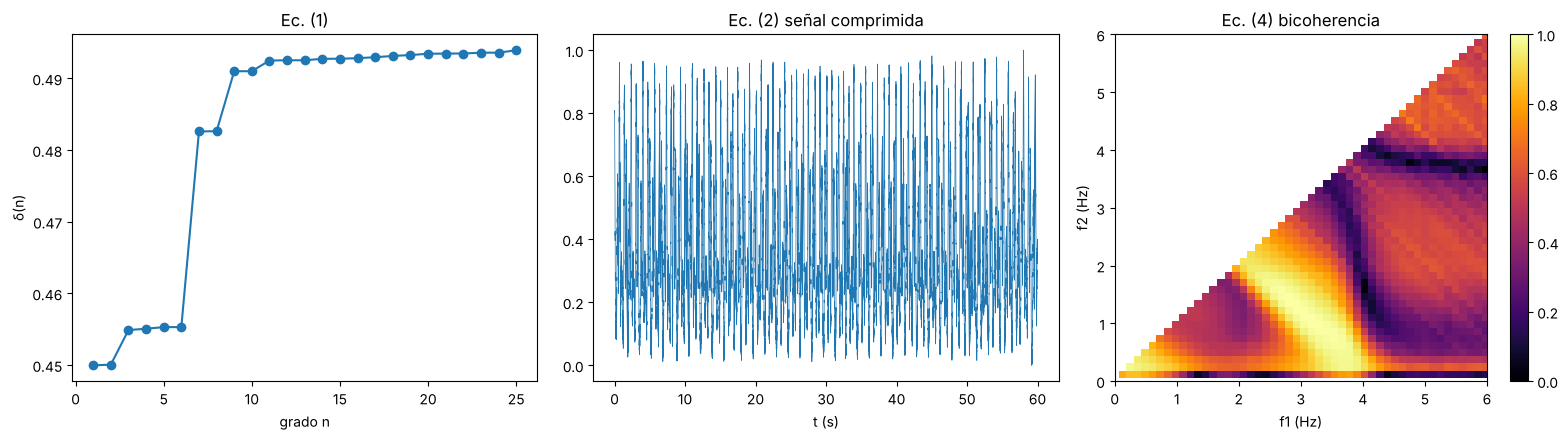

In [6]:
fs = 1000
t = np.arange(0, 60, 1/fs)
rng = np.random.default_rng(0)
x0 = 0.02 * t + 0.3 * np.sin(2*np.pi*0.05*t) + 0.05 * rng.standard_normal(t.size)
p1, p2 = 0.0, 0.0
nseg = 8192
for s in range(0, t.size, nseg):                     # fases aleatorias por segmento, acopladas en f1+f2
    sl = slice(s, s + nseg); p1, p2 = rng.uniform(0, 2*np.pi, 2)
    x0[sl] += (np.cos(2*np.pi*1.2*t[sl] + p1) + np.cos(2*np.pi*3*t[sl] + p2)
               + 0.5*np.cos(2*np.pi*4.2*t[sl] + p1 + p2))

# Ec. (1): δ(n) para varios grados
grados = range(1, 26)
deltas = [desviacion_detrending(x0, n)[0] for n in grados]
_, x_det = desviacion_detrending(x0, 20)

# Ec. (2)
s = compresion(x_det)
print("Rango comprimido:", s.min(), s.max())

# Ec. (3) y (4)
b, freqs, N = bispectro(s, fs)
B, freqs, umbral = bicoherencia(s, fs)
print(f"N = {N} segmentos, umbral de significancia = {umbral:.3f}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].plot(list(grados), deltas, "o-"); ax[0].set(xlabel="grado n", ylabel="δ(n)", title="Ec. (1)")
ax[1].plot(t, s, lw=0.5); ax[1].set(xlabel="t (s)", title="Ec. (2) señal comprimida")
im = ax[2].pcolormesh(freqs, freqs, B.T, shading="auto", cmap="inferno", vmin=0, vmax=1)
ax[2].set(xlabel="f1 (Hz)", ylabel="f2 (Hz)", xlim=(0, 6), ylim=(0, 6), title="Ec. (4) bicoherencia")
fig.colorbar(im, ax=ax[2]); plt.tight_layout(); plt.show()